# Zomato Exploratory Data Analysis Project

# Step 1 - Importing required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Step 2 - Loading the Dataset

In [2]:
df = pd.read_csv("zomato_data.csv")

In [3]:
df.head()

,Restaurant Name,Online_Order,Book_Table,Rate,Votes,Approx_Cost(For Two People),Listed_In(Type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet


In [5]:
df.shape

(148, 7)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   Restaurant Name              148 non-null    object
 1   Online_Order                 148 non-null    object
 2   Book_Table                   148 non-null    object
 3   Rate                         148 non-null    object
 4   Votes                        148 non-null    int64 
 5   Approx_Cost(For Two People)  148 non-null    int64 
 6   Listed_In(Type)              148 non-null    object
dtypes: int64(2), object(5)
memory usage: 8.2+ KB


In [8]:
df.describe(include='all')

,Restaurant Name,Online_Order,Book_Table,Rate,Votes,Approx_Cost(For Two People),Listed_In(Type)
count,148,148,148,148,148.000000,148.000000,148
unique,145,2,2,20,NaN,NaN,4
top,San Churro Cafe,No,No,3.8/5,NaN,NaN,Dining
freq,2,90,140,19,NaN,NaN,110
mean,NaN,NaN,NaN,NaN,264.810811,418.243243,NaN
std,NaN,NaN,NaN,NaN,653.676951,223.085098,NaN
min,NaN,NaN,NaN,NaN,0.000000,100.000000,NaN
25%,NaN,NaN,NaN,NaN,6.750000,200.000000,NaN
50%,NaN,NaN,NaN,NaN,43.500000,400.000000,NaN
75%,NaN,NaN,NaN,NaN,221.750000,600.000000,NaN


## Step 3 - Data Cleaning & Preparation

### 1.Convert the Rate Column to a Numeric Data Type

In [10]:
def handleRate(value):
    value = str(value).split('/')
    value = value[0]
    return float(value)
df['Rate'] = df['Rate'].apply(handleRate)
print(df.head(10))

                     Restaurant Name Online_Order Book_Table  Rate  Votes  \
0                              Jalsa          Yes        Yes   4.1    775   
1                     Spice Elephant          Yes         No   4.1    787   
2                    San Churro Cafe          Yes         No   3.8    918   
3              Addhuri Udupi Bhojana           No         No   3.7     88   
4                      Grand Village           No         No   3.8    166   
5                    Timepass Dinner          Yes         No   3.8    286   
6  Rosewood Hotel - Bar & Restaurant           No         No   3.6      8   
7                             Onesta          Yes        Yes   4.6   2556   
8                     Penthouse Cafe          Yes         No   4.0    324   
9                          Smacznego          Yes         No   4.2    504   

   Approx_Cost(For Two People) Listed_In(Type)  
0                          800          Buffet  
1                          800          Buffet  
2    

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Restaurant Name              148 non-null    object 
 1   Online_Order                 148 non-null    object 
 2   Book_Table                   148 non-null    object 
 3   Rate                         148 non-null    float64
 4   Votes                        148 non-null    int64  
 5   Approx_Cost(For Two People)  148 non-null    int64  
 6   Listed_In(Type)              148 non-null    object 
dtypes: float64(1), int64(2), object(4)
memory usage: 8.2+ KB


### 2.Standardize Column Names

In [12]:
df.columns = df.columns.str.lower()

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   restaurant name              148 non-null    object 
 1   online_order                 148 non-null    object 
 2   book_table                   148 non-null    object 
 3   rate                         148 non-null    float64
 4   votes                        148 non-null    int64  
 5   approx_cost(for two people)  148 non-null    int64  
 6   listed_in(type)              148 non-null    object 
dtypes: float64(1), int64(2), object(4)
memory usage: 8.2+ KB


### 3.Rename the Cost Column

In [19]:
df.rename(
    columns={'approx_cost(for two people)':'approx_cost'},inplace=True
)

In [ ]:
df.columns

### 4. Checking for Missing values & duplicates Records.

In [ ]:
print('Missing Values:')
print(df.isna().sum())
print('_'*20)
print(f'Duplicate Records:',df.duplicated().sum())

## Step 4 - Exploratory Data Analysis

### 1.How many customer votes has each restaurant type received?

In [33]:
grouped_data = df.groupby('listed_in(type)')['votes'].sum().reset_index()
grouped_data

,listed_in(type),votes
0,Buffet,3028
1,Cafes,6434
2,Dining,20363
3,other,9367


### 2.How many restaurant offer table booking?

In [40]:
result = df['book_table'].value_counts()
result

book_table
No     140
Yes      8
Name: count, dtype: int64

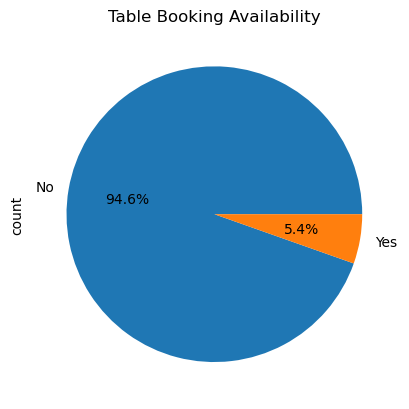

In [43]:
result.plot.pie(autopct='%1.1f%%')
plt.title('Table Booking Availability')
plt.show()

### 3.which five restaurants has highest number of votes?

In [46]:
top5 = df.nlargest(5,'votes')
print(top5[['restaurant name','votes']])


      restaurant name  votes
38  Empire Restaurant   4884
86      Meghana Foods   4401
7              Onesta   2556
44             Onesta   2556
65        Kabab Magic   1720


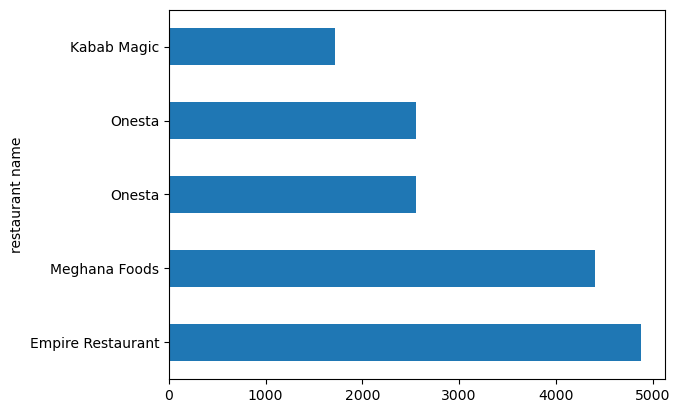

In [49]:
top5.plot.barh(x='restaurant name',y='votes',legend=False)
plt.show()

### Is there a relationship between ratings and customer votes?

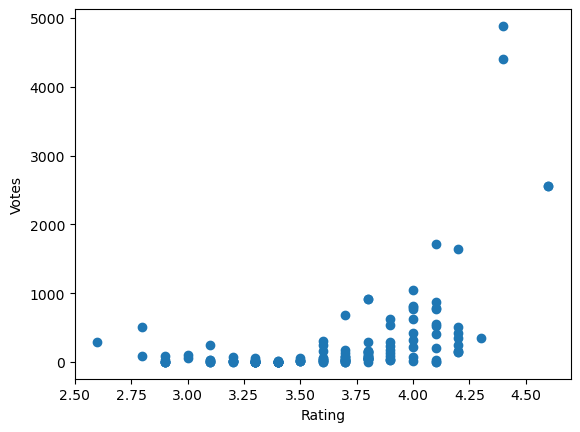

In [50]:
plt.scatter(df['rate'],df['votes'])
plt.xlabel('Rating')
plt.ylabel('Votes')
plt.show()

### 5. What is the average rating for each restaurant type?

In [56]:
result = df.groupby('listed_in(type)')['rate'].mean().round(2).sort_values(ascending=False)
result

listed_in(type)
other     3.91
Buffet    3.84
Cafes     3.77
Dining    3.57
Name: rate, dtype: float64

### 6.What type of restaurant do the majority of customers order from?

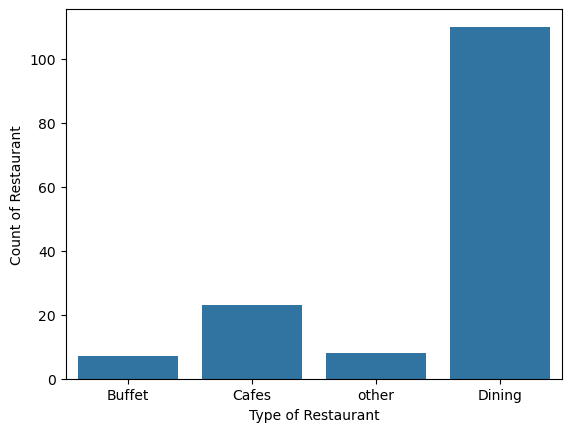

In [58]:
sns.countplot(x=df['listed_in(type)'])
plt.xlabel('Type of Restaurant')
plt.ylabel('Count of Restaurant')
plt.show()

### 7. What ratings do restaurants most commonly receive?

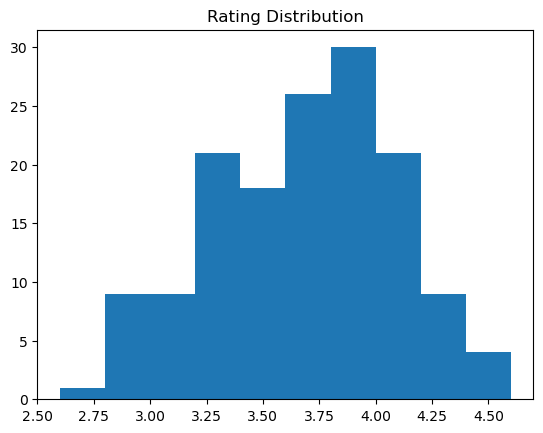

In [59]:
plt.hist(df['rate'],bins=10)
plt.title('Rating Distribution')
plt.show()

### 8.Which restaurant type has the highest average cost for two people?

In [60]:
result = df.groupby('listed_in(type)')['approx_cost'].mean()
result.sort_values(ascending=False)

listed_in(type)
Buffet    671.428571
other     668.750000
Cafes     545.652174
Dining    357.272727
Name: approx_cost, dtype: float64

### 9.Which order mode - Online or Offline - gets better ratings?


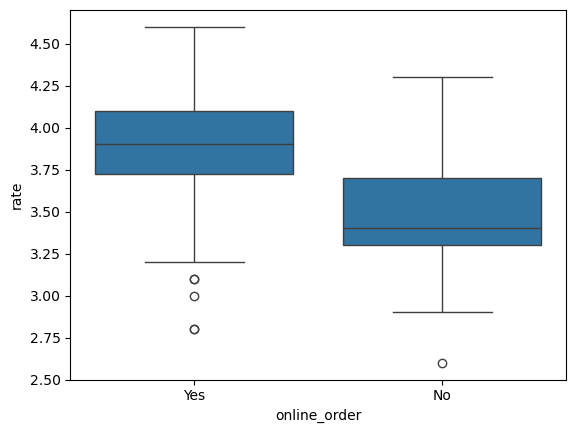

In [63]:
sns.boxplot(x='online_order',y='rate',data=df)
plt.show()

### 10.Which restaurant type have more offline-ordering records?

In [64]:
pivot_table = df.pivot_table(
    index='listed_in(type)',
    columns='online_order',
    aggfunc='size',
    fill_value=0
)
pivot_table

online_order,No,Yes
listed_in(type),,
Buffet,3,4
Cafes,8,15
Dining,77,33
other,2,6


In [ ]:
sns.heatmap(
    pivot_table,annot=True,cmap='YlGnBu',fmt='d'
)
plt.title('Heatmap')
plt.xlabel('Online_order')
plt.ylabel('Listed In')